In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("dataset.csv")

In [3]:
pd.set_option("display.max_columns", None)
df.head(10)

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,Suburban,Married,69,32,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,Suburban,Single,94,13,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,Suburban,Married,108,18,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,Suburban,Married,106,18,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,2/3/11,Employed,M,43836,Rural,Single,73,12,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize
5,OC83172,Oregon,8256.297800,Yes,Basic,Bachelor,1/25/11,Employed,F,62902,Rural,Married,69,14,94,0,2,Personal Auto,Personal L3,Offer2,Web,159.383042,Two-Door Car,Medsize
6,XZ87318,Oregon,5380.898636,Yes,Basic,College,2/24/11,Employed,F,55350,Suburban,Married,67,0,13,0,9,Corporate Auto,Corporate L3,Offer1,Agent,321.600000,Four-Door Car,Medsize
7,CF85061,Arizona,7216.100311,No,Premium,Master,1/18/11,Unemployed,M,0,Urban,Single,101,0,68,0,4,Corporate Auto,Corporate L3,Offer1,Agent,363.029680,Four-Door Car,Medsize
8,DY87989,Oregon,24127.504020,Yes,Basic,Bachelor,1/26/11,Medical Leave,M,14072,Suburban,Divorced,71,13,3,0,2,Corporate Auto,Corporate L3,Offer1,Agent,511.200000,Four-Door Car,Medsize
9,BQ94931,Oregon,7388.178085,No,Extended,College,2/17/11,Employed,F,28812,Urban,Married,93,17,7,0,8,Special Auto,Special L2,Offer2,Branch,425.527834,Four-Door Car,Medsize


In [4]:
df.shape
#24 columns 

(9134, 24)

In [5]:
df.info()
#Change the datatype of Date
#There are no Null Values

<class 'pandas.DataFrame'>
RangeIndex: 9134 entries, 0 to 9133
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer                       9134 non-null   str    
 1   State                          9134 non-null   str    
 2   Customer Lifetime Value        9134 non-null   float64
 3   Response                       9134 non-null   str    
 4   Coverage                       9134 non-null   str    
 5   Education                      9134 non-null   str    
 6   Effective To Date              9134 non-null   str    
 7   EmploymentStatus               9134 non-null   str    
 8   Gender                         9134 non-null   str    
 9   Income                         9134 non-null   int64  
 10  Location Code                  9134 non-null   str    
 11  Marital Status                 9134 non-null   str    
 12  Monthly Premium Auto           9134 non-null   int64  
 13 

In [6]:
df.describe()

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
count,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000
mean,8004.940475,37657.380009,93.219291,15.097000,48.064594,0.384388,2.966170,434.088794
std,6870.967608,30379.904734,34.407967,10.073257,27.905991,0.910384,2.390182,290.500092
min,1898.007675,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007
25%,3994.251794,0.000000,68.000000,6.000000,24.000000,0.000000,1.000000,272.258244
50%,5780.182197,33889.500000,83.000000,14.000000,48.000000,0.000000,2.000000,383.945434
75%,8962.167041,62320.000000,109.000000,23.000000,71.000000,0.000000,4.000000,547.514839
max,83325.381190,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678


In [7]:
df.duplicated().sum()
#0 duplicates

0

Boxplots 


In [8]:
numeric=[col for col in df.columns if df[col].dtype in ["int64", "int32", "int"]]
def categorical(columns):
    figure=plt.figure(figsize=(5,6))
    for i,col in enumerate(columns[:4],start=1):
        ax=figure.add_subplot(2,2,i)
        plt.figure()
        sns.boxplot(data=df,x=col,ax=ax)
        ax.set_title(f"Boxplot of {col}")
    figure.tight_layout()
    figure.show()
        

C:\Users\MAS LAPTOP\AppData\Local\Temp\ipykernel_8988\1577339754.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  figure.show()


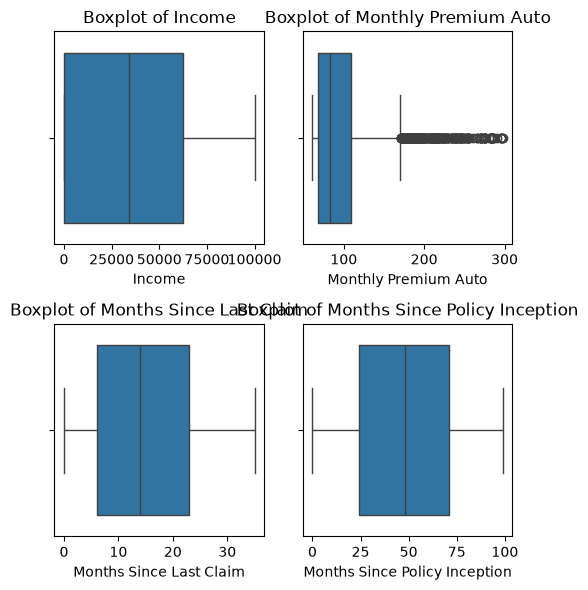

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [9]:
categorical(numeric)

In [10]:
#There are lot of outliers in monthly premium autos
#Lets analyze it
df['Monthly Premium Auto'].describe()

count    9134.000000
mean       93.219291
std        34.407967
min        61.000000
25%        68.000000
50%        83.000000
75%       109.000000
max       298.000000
Name: Monthly Premium Auto, dtype: float64

In [11]:
df[df['Monthly Premium Auto']>110]

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
26,US89481,California,3946.372085,No,Premium,Bachelor,2/28/11,Unemployed,F,0,Suburban,Single,111,15,47,0,1,Personal Auto,Personal L3,Offer1,Agent,799.200000,Four-Door Car,Small
27,HO30839,Washington,5346.916576,No,Extended,Master,2/12/11,Disabled,F,10511,Urban,Married,139,33,64,0,1,Corporate Auto,Corporate L1,Offer1,Branch,516.237951,SUV,Medsize
28,GE62437,Arizona,12902.560140,No,Premium,College,2/2/11,Employed,F,86584,Suburban,Single,111,33,54,2,2,Personal Auto,Personal L3,Offer1,Call Center,532.800000,Four-Door Car,Large
31,UL64533,Nevada,18975.456110,No,Extended,High School or Below,1/22/11,Employed,M,65999,Urban,Married,237,1,14,0,6,Corporate Auto,Corporate L2,Offer2,Agent,615.927769,Luxury SUV,Medsize
36,KY38074,California,13891.735670,No,Premium,Bachelor,1/8/11,Employed,M,42305,Suburban,Married,117,10,62,0,2,Personal Auto,Personal L3,Offer1,Agent,561.600000,Four-Door Car,Small
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9112,ZP86347,California,5500.577411,No,Extended,College,2/12/11,Employed,F,44019,Rural,Married,138,20,60,0,1,Personal Auto,Personal L3,Offer3,Agent,165.478147,SUV,Medsize
9118,OT56964,California,9424.256842,No,Basic,Master,2/10/11,Employed,M,46897,Urban,Married,118,13,11,0,3,Corporate Auto,Corporate L3,Offer1,Agent,322.575677,SUV,Medsize
9121,BB10681,California,4140.648654,No,Extended,College,1/17/11,Unemployed,F,0,Suburban,Divorced,123,5,35,2,1,Corporate Auto,Corporate L3,Offer1,Branch,590.400000,SUV,Medsize
9124,CB59349,California,16261.585500,No,Extended,Master,1/20/11,Employed,M,60646,Suburban,Married,134,31,42,0,2,Personal Auto,Personal L3,Offer2,Agent,643.200000,SUV,Medsize


In [12]:
df["Monthly Premium Auto"] = np.log1p(df["Monthly Premium Auto"])

In [13]:
print((df["Income"] == 0).sum())
print((df["Income"] == 0).mean() * 100)

2317
25.366761550251805


In [14]:
df[df["Income"] == 0].describe()

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
count,2317.000000,2317.0,2317.000000,2317.000000,2317.000000,2317.000000,2317.000000,2317.000000
mean,7636.319761,0.0,4.503003,15.244281,48.747087,0.391886,3.010790,599.579795
std,6623.586963,0.0,0.304122,10.098944,27.932127,0.926059,2.388871,328.967738
min,1898.007675,0.0,4.127134,0.000000,0.000000,0.000000,1.000000,2.455033
25%,3761.792015,0.0,4.248495,6.000000,26.000000,0.000000,1.000000,379.200000
50%,5619.689084,0.0,4.442651,14.000000,48.000000,0.000000,2.000000,524.836298
75%,8532.718297,0.0,4.709530,23.000000,72.000000,0.000000,4.000000,731.479725
max,74228.516040,0.0,5.700444,35.000000,99.000000,5.000000,9.000000,2759.794354


In [15]:
df["Income_Zero"] = (df["Income"] == 0).astype(int)

In [16]:
df.groupby(df['Income']==0)['Customer Lifetime Value'].agg(
    ['count','mean','median']
)

,count,mean,median
Income,,,
False,6817,8130.229340,5810.630529
True,2317,7636.319761,5619.689084


In [17]:
df['Effective To Date'] = pd.to_datetime(df['Effective To Date'], format='mixed', errors='coerce')

In [18]:
df.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size,Income_Zero
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2011-02-24,Employed,F,56274,Suburban,Married,4.248495,32,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize,0
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,2011-01-31,Unemployed,F,0,Suburban,Single,4.553877,13,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize,1
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2011-02-19,Employed,F,48767,Suburban,Married,4.691348,18,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize,0
3,WW63253,California,7645.861827,No,Basic,Bachelor,2011-01-20,Unemployed,M,0,Suburban,Married,4.672829,18,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize,1
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,2011-02-03,Employed,M,43836,Rural,Single,4.304065,12,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize,0


In [19]:
df['Response']=df['Response'].replace({"Yes":1,"No":0}).astype(int)

In [20]:
df['Gender']=df['Gender'].replace({"M":1,"F":0}).astype(int)

In [21]:
ordinalcols=['Coverage','Education','Vehicle Size']
onehotcols=['Vehicle Class','EmploymentStatus','Policy Type','Policy','Renew Offer Type','Sales Channel','Marital Status','State','Location Code']

In [22]:
from sklearn.preprocessing import OrdinalEncoder
ordinal_categories = [['Basic', 'Extended', 'Premium'],
    ['High School or Below', 'College', 'Bachelor', 'Master', 'Doctor'],
    ['Small', 'Medsize', 'Large']]

In [23]:
ordinal_encoder = OrdinalEncoder(categories=ordinal_categories)

In [24]:
df[ordinalcols] = ordinal_encoder.fit_transform(df[ordinalcols])

In [25]:
df2=df.copy()

In [26]:
df=pd.get_dummies(df,columns=onehotcols,drop_first=True,dtype=int)


In [27]:
df.head()

,Customer,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,Gender,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount,Vehicle Size,Income_Zero,Vehicle Class_Luxury Car,Vehicle Class_Luxury SUV,Vehicle Class_SUV,Vehicle Class_Sports Car,Vehicle Class_Two-Door Car,EmploymentStatus_Employed,EmploymentStatus_Medical Leave,EmploymentStatus_Retired,EmploymentStatus_Unemployed,Policy Type_Personal Auto,Policy Type_Special Auto,Policy_Corporate L2,Policy_Corporate L3,Policy_Personal L1,Policy_Personal L2,Policy_Personal L3,Policy_Special L1,Policy_Special L2,Policy_Special L3,Renew Offer Type_Offer2,Renew Offer Type_Offer3,Renew Offer Type_Offer4,Sales Channel_Branch,Sales Channel_Call Center,Sales Channel_Web,Marital Status_Married,Marital Status_Single,State_California,State_Nevada,State_Oregon,State_Washington,Location Code_Suburban,Location Code_Urban
0,BU79786,2763.519279,0,0.0,2.0,2011-02-24,0,56274,4.248495,32,5,0,1,384.811147,1.0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,1,0
1,QZ44356,6979.535903,0,1.0,2.0,2011-01-31,0,0,4.553877,13,42,0,8,1131.464935,1.0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0
2,AI49188,12887.431650,0,2.0,2.0,2011-02-19,0,48767,4.691348,18,38,0,2,566.472247,1.0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0
3,WW63253,7645.861827,0,0.0,2.0,2011-01-20,1,0,4.672829,18,65,0,7,529.881344,1.0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0
4,HB64268,2813.692575,0,0.0,2.0,2011-02-03,1,43836,4.304065,12,44,0,1,138.130879,1.0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0


In [28]:
df['Month'] = pd.to_datetime(df['Effective To Date']).dt.month
df['date']=pd.to_datetime(df['Effective To Date']).dt.day
df['year']=pd.to_datetime(df['Effective To Date']).dt.year

In [29]:
df.drop(columns=['Customer','Effective To Date'],inplace=True)

In [30]:
pos=[]
neg=[]
norm=[]

In [31]:
df.skew()

Customer Lifetime Value            3.032280
Response                           2.037567
Coverage                           1.031310
Education                          0.508900
Gender                             0.039866
Income                             0.286887
Monthly Premium Auto               1.013663
Months Since Last Claim            0.278586
Months Since Policy Inception      0.040165
Number of Open Complaints          2.783263
Number of Policies                 1.253333
Total Claim Amount                 1.714966
Vehicle Size                      -0.072742
Income_Zero                        1.132463
Vehicle Class_Luxury Car           7.285081
Vehicle Class_Luxury SUV           6.832071
Vehicle Class_SUV                  1.526848
Vehicle Class_Sports Car           3.991627
Vehicle Class_Two-Door Car         1.450502
EmploymentStatus_Employed         -0.511300
EmploymentStatus_Medical Leave     4.266045
EmploymentStatus_Retired           5.425089
EmploymentStatus_Unemployed     

In [32]:
df['Customer Lifetime Value'].skew()
for col in df.columns:
    s=df[col].skew()
    if s>=-0.5 and s<=0.5:
        norm.append(col)
    elif s>=1:
        pos.append(col)
    else:
        neg.append(col)

In [33]:
print(pos)
print(neg)
print(norm)

['Customer Lifetime Value', 'Response', 'Coverage', 'Monthly Premium Auto', 'Number of Open Complaints', 'Number of Policies', 'Total Claim Amount', 'Income_Zero', 'Vehicle Class_Luxury Car', 'Vehicle Class_Luxury SUV', 'Vehicle Class_SUV', 'Vehicle Class_Sports Car', 'Vehicle Class_Two-Door Car', 'EmploymentStatus_Medical Leave', 'EmploymentStatus_Retired', 'EmploymentStatus_Unemployed', 'Policy Type_Special Auto', 'Policy_Corporate L2', 'Policy_Corporate L3', 'Policy_Personal L1', 'Policy_Personal L2', 'Policy_Special L1', 'Policy_Special L2', 'Policy_Special L3', 'Renew Offer Type_Offer3', 'Renew Offer Type_Offer4', 'Sales Channel_Call Center', 'Sales Channel_Web', 'Marital Status_Single', 'State_Nevada', 'State_Washington', 'Location Code_Urban']
['Education', 'EmploymentStatus_Employed', 'Policy Type_Personal Auto', 'Policy_Personal L3', 'Renew Offer Type_Offer2', 'Sales Channel_Branch', 'State_California', 'State_Oregon', 'Location Code_Suburban']
['Gender', 'Income', 'Months Sin

In [34]:
df[pos] = np.log1p(df[pos]) 
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')
df[neg] = pt.fit_transform(df[neg])

In [35]:
X=df.drop('Customer Lifetime Value',axis=1)
y=df['Customer Lifetime Value']

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [37]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [38]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
model=Sequential([
    Dense(64,activation='relu',input_shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32,activation='relu'),
    Dense(1)
])

c:\Users\MAS LAPTOP\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [40]:
model.compile(optimizer='adam',loss='mse',metrics=['mse'])
history=model.fit(X_train_scaled,y_train,epochs=50,batch_size=32,validation_split=0.20,verbose=2)

Epoch 1/50
183/183 - 5s - 26ms/step - loss: 7.3992 - mse: 7.3992 - val_loss: 0.9462 - val_mse: 0.9462
Epoch 2/50
183/183 - 2s - 10ms/step - loss: 0.7727 - mse: 0.7727 - val_loss: 0.7592 - val_mse: 0.7592
Epoch 3/50
183/183 - 1s - 5ms/step - loss: 0.5854 - mse: 0.5854 - val_loss: 0.5977 - val_mse: 0.5977
Epoch 4/50
183/183 - 1s - 8ms/step - loss: 0.4870 - mse: 0.4870 - val_loss: 0.5377 - val_mse: 0.5377
Epoch 5/50
183/183 - 1s - 4ms/step - loss: 0.4192 - mse: 0.4192 - val_loss: 0.4910 - val_mse: 0.4910
Epoch 6/50
183/183 - 1s - 4ms/step - loss: 0.3753 - mse: 0.3753 - val_loss: 0.4752 - val_mse: 0.4752
Epoch 7/50
183/183 - 1s - 4ms/step - loss: 0.3369 - mse: 0.3369 - val_loss: 0.4238 - val_mse: 0.4238
Epoch 8/50
183/183 - 1s - 5ms/step - loss: 0.2906 - mse: 0.2906 - val_loss: 0.3716 - val_mse: 0.3716
Epoch 9/50
183/183 - 1s - 4ms/step - loss: 0.2350 - mse: 0.2350 - val_loss: 0.2971 - val_mse: 0.2971
Epoch 10/50
183/183 - 1s - 6ms/step - loss: 0.1770 - mse: 0.1770 - val_loss: 0.2433 - val

In [41]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
y_pred = model.predict(X_test_scaled).flatten()
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
MAE: 0.2772389694186963
RMSE: 0.35954634112928013
R²: 0.7079550002094732


In [42]:
coor_matrix=df.corr()
CLV_correlations = coor_matrix['Customer Lifetime Value'].sort_values(ascending=False)
print("--- STRONGEST RELATIONSHIPS WITH CHURN ---")
print("\nTop factors for CLV (Positive Correlation):")
print(CLV_correlations.head(10)) 
print("\nTop -ive factorsfor CLV(Negative Correlation):")
print(CLV_correlations.tail(10))
print("-" * 42)

--- STRONGEST RELATIONSHIPS WITH CHURN ---

Top factors for CLV (Positive Correlation):
Customer Lifetime Value      1.000000
Monthly Premium Auto         0.461804
Number of Policies           0.309573
Vehicle Class_SUV            0.231354
Coverage                     0.220366
Vehicle Class_Luxury SUV     0.177186
Vehicle Class_Luxury Car     0.168332
Total Claim Amount           0.156764
Vehicle Class_Sports Car     0.117548
EmploymentStatus_Employed    0.056566
Name: Customer Lifetime Value, dtype: float64

Top -ive factorsfor CLV(Negative Correlation):
Sales Channel_Web             -0.020800
Education                     -0.024510
Number of Open Complaints     -0.037979
Marital Status_Single         -0.040203
EmploymentStatus_Unemployed   -0.045769
Income_Zero                   -0.045769
Renew Offer Type_Offer4       -0.062638
Renew Offer Type_Offer2       -0.082814
Vehicle Class_Two-Door Car    -0.117561
year                                NaN
Name: Customer Lifetime Value, dtype: 

In [43]:
upper=coor_matrix.where(np.triu(np.ones(coor_matrix.shape),k=1).astype(bool))
todrop=[col for col in upper.columns if any (abs(upper[col])>0.8)]
todrop

['EmploymentStatus_Unemployed']

In [44]:
from sklearn.feature_selection import mutual_info_regression
mi = mutual_info_regression(X_train, y_train, random_state=42)
mi_scores = pd.Series(mi, index=X_train.columns).sort_values(ascending=False)
print(mi_scores)

Monthly Premium Auto              1.650748
Total Claim Amount                1.067551
Income                            0.883224
Number of Policies                0.784826
Months Since Policy Inception     0.593475
Months Since Last Claim           0.440024
date                              0.436250
Coverage                          0.317962
Response                          0.301623
Education                         0.164698
Vehicle Class_SUV                 0.145893
EmploymentStatus_Employed         0.113103
Renew Offer Type_Offer2           0.103021
Vehicle Size                      0.093849
Marital Status_Married            0.092685
Number of Open Complaints         0.085414
EmploymentStatus_Unemployed       0.084236
Income_Zero                       0.084219
EmploymentStatus_Retired          0.082407
Marital Status_Single             0.081793
Month                             0.077508
Location Code_Suburban            0.076927
Gender                            0.074179
Vehicle Cla

In [45]:
from sklearn.feature_selection import SelectKBest
selector = SelectKBest(mutual_info_regression, k=10).fit(X, y)
selected = X.columns[selector.get_support()].tolist()

In [46]:
selected

['Response',
 'Coverage',
 'Education',
 'Income',
 'Monthly Premium Auto',
 'Months Since Last Claim',
 'Months Since Policy Inception',
 'Number of Policies',
 'Total Claim Amount',
 'date']

In [47]:
X_train_new, X_test_new, y_train_new, y_test_new=train_test_split(X[selected],y,test_size=0.2,random_state=42)

In [48]:
X_train_new

,Response,Coverage,Education,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Policies,Total Claim Amount,date
5123,0.000000,0.000000,0.751755,51144,1.634547,28,32,2.302585,5.413008,10
7738,0.000000,0.693147,-0.098236,0,1.683065,30,25,0.693147,6.345285,18
214,0.000000,0.000000,-0.098236,81097,1.671001,7,67,0.693147,5.875492,28
8580,0.000000,0.000000,0.751755,72264,1.643721,2,66,2.302585,5.611849,8
7857,0.000000,0.000000,0.751755,54737,1.649561,3,86,0.693147,5.973734,18
...,...,...,...,...,...,...,...,...,...,...
5734,0.000000,0.000000,-0.098236,87957,1.634547,31,63,1.098612,5.734381,29
5191,0.693147,0.000000,-0.098236,22520,1.668474,17,64,1.386294,5.861925,5
5390,0.000000,0.693147,-1.344693,0,1.769435,13,4,2.079442,6.966564,27
860,0.693147,0.693147,0.751755,0,1.781986,5,56,1.098612,6.504588,27


In [49]:
X_train_new_scaled=scaler.fit_transform(X_train_new)
X_test_new_scaled=scaler.transform(X_test_new)

In [50]:
model2=Sequential([
    Dense(64,activation='relu',input_shape=(X_train_new_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32,activation='relu'),
    Dense(1)
])
model2.compile(optimizer='adam',loss='mse',metrics=['mse'])

c:\Users\MAS LAPTOP\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [51]:
history2=model2.fit(X_train_new_scaled,y_train_new,epochs=50,batch_size=32,validation_split=0.20,verbose=2)


Epoch 1/50
183/183 - 4s - 21ms/step - loss: 9.2753 - mse: 9.2753 - val_loss: 1.6201 - val_mse: 1.6201
Epoch 2/50
183/183 - 1s - 4ms/step - loss: 1.2970 - mse: 1.2970 - val_loss: 1.0458 - val_mse: 1.0458
Epoch 3/50
183/183 - 1s - 6ms/step - loss: 0.8032 - mse: 0.8032 - val_loss: 0.6011 - val_mse: 0.6011
Epoch 4/50
183/183 - 1s - 5ms/step - loss: 0.4218 - mse: 0.4218 - val_loss: 0.3314 - val_mse: 0.3314
Epoch 5/50
183/183 - 1s - 4ms/step - loss: 0.2091 - mse: 0.2091 - val_loss: 0.1519 - val_mse: 0.1519
Epoch 6/50
183/183 - 1s - 7ms/step - loss: 0.1312 - mse: 0.1312 - val_loss: 0.1098 - val_mse: 0.1098
Epoch 7/50
183/183 - 1s - 5ms/step - loss: 0.1019 - mse: 0.1019 - val_loss: 0.0988 - val_mse: 0.0988
Epoch 8/50
183/183 - 1s - 4ms/step - loss: 0.0897 - mse: 0.0897 - val_loss: 0.0920 - val_mse: 0.0920
Epoch 9/50
183/183 - 1s - 4ms/step - loss: 0.0813 - mse: 0.0813 - val_loss: 0.0783 - val_mse: 0.0783
Epoch 10/50
183/183 - 1s - 4ms/step - loss: 0.0734 - mse: 0.0734 - val_loss: 0.0786 - val_

In [52]:
y_pred = model2.predict(X_test_new_scaled).flatten()
mae = mean_absolute_error(y_test_new, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_new, y_pred))
r2 = r2_score(y_test_new, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
MAE: 0.15705846060999404
RMSE: 0.22422950707608838
R²: 0.8864138048032739


In [53]:
Adjusted_R2 = 1 - ((1-r2)*(X_train_new.shape[0]-1)) / (X_train_new.shape[0]-X_train_new.shape[1]-1)
print(Adjusted_R2)

0.886258121969945


In [55]:
from tensorflow.keras.layers import (Dropout,BatchNormalization)
from tensorflow.keras.callbacks import (
    EarlyStopping,ReduceLROnPlateau)
final_model=Sequential([
    Dense(64,activation='relu',input_shape=(X_train_new_scaled.shape[1],)),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dense(64, activation='relu'),
    Dropout(0.25),
    Dense(32,activation='relu'),
    Dense(1)
])
final_model.compile(optimizer='adam',loss='mse',metrics=['mse'])

c:\Users\MAS LAPTOP\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [56]:
earlystop=EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=5,min_lr=0.00001, verbose=1)
history=final_model.fit(X_train_new_scaled,y_train_new,epochs=60,batch_size=32,validation_split=0.20,verbose=2,callbacks=[earlystop,reduce_lr])


Epoch 1/60
183/183 - 6s - 31ms/step - loss: 10.3567 - mse: 10.3567 - val_loss: 21.2713 - val_mse: 21.2713 - learning_rate: 0.0010
Epoch 2/60
183/183 - 2s - 8ms/step - loss: 2.0237 - mse: 2.0237 - val_loss: 3.0783 - val_mse: 3.0783 - learning_rate: 0.0010
Epoch 3/60
183/183 - 2s - 12ms/step - loss: 1.6039 - mse: 1.6039 - val_loss: 0.5020 - val_mse: 0.5020 - learning_rate: 0.0010
Epoch 4/60
183/183 - 1s - 7ms/step - loss: 1.4431 - mse: 1.4431 - val_loss: 0.4383 - val_mse: 0.4383 - learning_rate: 0.0010
Epoch 5/60
183/183 - 1s - 5ms/step - loss: 1.2158 - mse: 1.2158 - val_loss: 0.3865 - val_mse: 0.3865 - learning_rate: 0.0010
Epoch 6/60
183/183 - 1s - 5ms/step - loss: 1.1037 - mse: 1.1037 - val_loss: 0.3805 - val_mse: 0.3805 - learning_rate: 0.0010
Epoch 7/60
183/183 - 1s - 5ms/step - loss: 0.9432 - mse: 0.9432 - val_loss: 0.3126 - val_mse: 0.3126 - learning_rate: 0.0010
Epoch 8/60
183/183 - 1s - 7ms/step - loss: 0.8250 - mse: 0.8250 - val_loss: 0.2504 - val_mse: 0.2504 - learning_rate: 0

In [57]:
y_pred = model2.predict(X_test_new_scaled).flatten()
mae = mean_absolute_error(y_test_new, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_new, y_pred))
r2 = r2_score(y_test_new, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
MAE: 0.15705846060999404
RMSE: 0.22422950707608838
R²: 0.8864138048032739


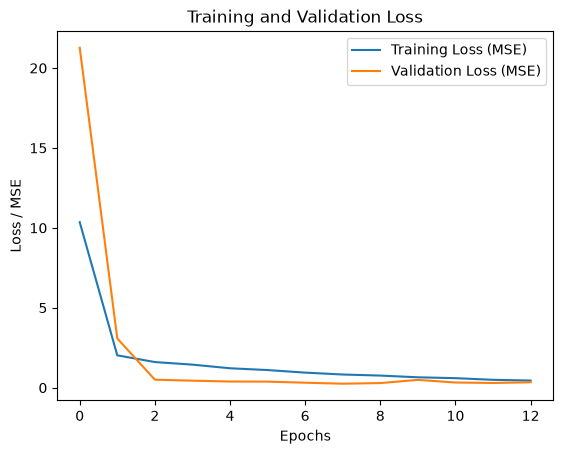

In [61]:
plt.plot(history.history['loss'], label='Training Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss / MSE')
plt.legend()
plt.show()

In [ ]:
# Save trained model using Keras for Streamlit UI deployment
final_model.save('final_model.keras')
import joblib
joblib.dump(scaler, 'scaler.joblib')
print('Saved model to final_model.keras and scaler to scaler.joblib!')
